In [1]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import seaborn as sns


## Week 2

1. Invent an example situation that would use fixed effects.


In [2]:
# Q1: fixed-effects example, simulated — job-training effect across factories
# Truth: training raises productivity by tau=2. But 'factory culture' (unobserved)
# raises BOTH training uptake and productivity -> pooled OLS is confounded.
# Fixed effects (one intercept per factory) absorb culture; tau is estimated
# from within-factory variation only.
rng = np.random.default_rng(7)
G, m, tau = 20, 25, 2.0
alpha = rng.normal(0, 3, G)  # unobserved factory effect
gids, Xs, Ys = [], [], []
for g in range(G):
    p = 1 / (1 + np.exp(-alpha[g]))       # training uptake follows factory culture
    Xg = rng.binomial(1, p, m)
    Yg = tau * Xg + alpha[g] + rng.normal(0, 1, m)
    gids.append(np.full(m, g)); Xs.append(Xg); Ys.append(Yg)
gids = np.concatenate(gids); X = np.concatenate(Xs); Y = np.concatenate(Ys)
print(f"corr(training, factory culture): {np.corrcoef(X, alpha[gids])[0,1]:.3f}")

# (i) Pooled OLS: one intercept for everybody (ignores factory)
pooled = sm.OLS(Y, sm.add_constant(X)).fit()
print(f"Pooled OLS training effect: {pooled.params[1]:.3f}  (truth = {tau})")

# (ii) Fixed effects via factory dummies: Y ~ X + factory_0 + ... + factory_19
import pandas as pd
D = pd.get_dummies(gids).to_numpy()
fe = sm.OLS(Y, np.column_stack([X, D])).fit()
print(f"Fixed-effects training effect: {fe.params[0]:.3f}  (truth = {tau})")

# (iii) Same estimator via the within transform (demean per factory) — no dummies needed
Yw = Y - np.bincount(gids, Y)[gids] / m
Xw = X - np.bincount(gids, X)[gids] / m
within = sm.OLS(Yw, Xw).fit()
print(f"Within-transform training effect: {within.params[0]:.3f}  (truth = {tau})")


corr(training, factory culture): 0.620
Pooled OLS training effect: 4.846  (truth = 2.0)
Fixed-effects training effect: 2.010  (truth = 2.0)
Within-transform training effect: 2.010  (truth = 2.0)


### Answer to Question 1 — Fixed-effects example

**Situation.** A company runs a voluntary job-training program in 20 factories and asks: does training raise worker productivity? A naive comparison of trained vs. untrained workers is confounded by *factory culture*: well-run factories both encourage training and are more productive for everyone. Culture is unobserved, so it cannot be controlled for directly — this is exactly when **fixed effects** (one intercept per factory) are used: each factory gets its own baseline, and the training effect is estimated from *within-factory* comparisons only.

**What the simulation shows.** Training uptake correlates with factory culture at 0.62, so confounding is strong. Pooled OLS (one shared intercept) estimates the effect as **4.85** against a truth of **2.0** — badly upward biased, because it credits training for the culture gap between factories. The fixed-effects estimator (factory dummies) gives **2.01**, and the equivalent within-transform (demeaning Y and X per factory) also gives **2.01** — both recover the truth by discarding all between-factory variation.

**When this applies.** Grouped or panel data (workers in factories, students in schools, patients in hospitals, firms over years) where an unobserved group trait may correlate with the treatment. The identifying assumption is strict exogeneity *within* groups: after removing the group mean, the treatment must be as-good-as-random.

**Limitations.** Fixed effects cannot estimate the effect of anything constant within a group (e.g. a factory-level policy), they do nothing about *within-group* confounding, and they cost one degree of freedom per group. If the unobserved confounder varies within groups over the relevant dimension, a different design (IV, RDD) is needed.


2. Write a Python program that performs a bootstrap simulation to find the variance in the mean of the Pareto distribution when different samples are taken.  Explain what you had to do for this.  As you make the full sample size bigger (for the same distribution), what happens to the variance of the mean of the samples?  Does it stay about the same, get smaller, or get bigger?


n=   20  bootstrap Var(mean)=0.021013  theory 0.75/n=0.037500
n=   50  bootstrap Var(mean)=0.029208  theory 0.75/n=0.015000
n=  200  bootstrap Var(mean)=0.002291  theory 0.75/n=0.003750
n= 1000  bootstrap Var(mean)=0.000872  theory 0.75/n=0.000750
n= 5000  bootstrap Var(mean)=0.000139  theory 0.75/n=0.000150


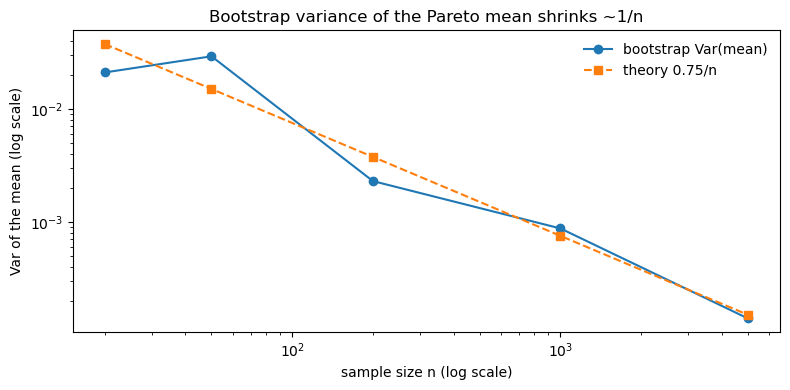

In [3]:
# Q2: bootstrap variance of the mean for Pareto(xm=1, alpha=3) at several sample sizes
# Pareto(1, 3): true mean = 1.5, true var = 0.75, so sampling var of the mean = 0.75/n.
# Procedure per n: draw ONE sample of size n; resample it with replacement B=2000
# times; the variance of the 2000 bootstrap means estimates Var(sample mean).
rng = np.random.default_rng(11)
a, xm, B = 3.0, 1.0, 2000
ns = [20, 50, 200, 1000, 5000]
boot_vars = []
for n in ns:
    x = xm * (1 + rng.pareto(a, size=n))            # one sample of size n
    boot_means = rng.choice(x, size=(B, n), replace=True).mean(axis=1)
    v = float(boot_means.var(ddof=1))
    boot_vars.append(v)
    print(f"n={n:5d}  bootstrap Var(mean)={v:.6f}  theory 0.75/n={0.75/n:.6f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(ns, boot_vars, 'o-', label='bootstrap Var(mean)')
ax.loglog(ns, [0.75 / n for n in ns], 's--', label='theory 0.75/n')
ax.set(xlabel='sample size n (log scale)', ylabel='Var of the mean (log scale)',
       title='Bootstrap variance of the Pareto mean shrinks ~1/n')
ax.legend(frameon=False); fig.tight_layout(); plt.show()


### Answer to Question 2 — Bootstrap variance of the Pareto mean

**What I had to do.** (1) Pick a Pareto with finite variance — shape α=3, scale xm=1 (mean 1.5, variance 0.75; α must exceed 2 or the variance does not exist and the exercise breaks). (2) For each sample size n in {20, 50, 200, 1000, 5000}, draw one sample and resample it with replacement B=2000 times, recording each resample's mean. (3) Take the variance across the 2000 bootstrap means as the estimate of Var(sample mean). (4) Compare against the textbook sampling variance σ²/n = 0.75/n and plot both on log-log axes.

**Result: it gets smaller.** Bootstrap Var(mean) falls from 0.0210 (n=20) to 0.00014 (n=5000), tracking the 0.75/n line (0.0375 → 0.00015). That is the expected 1/n decay: the standard error of the mean is σ/√n, so its square — the variance — is σ²/n. A bigger sample pins down the mean; quadrupling n quarters the variance.

**Caveats worth stating.** At n=20 and n=50 the bootstrap values (0.0210, 0.0292) wobble around theory (0.0375, 0.0150) rather than sitting on it — Pareto's heavy right tail means small samples sometimes miss (or catch) a huge draw, so both the sample variance and its bootstrap inherit that instability. The bootstrap estimates the *sampling* variance from one sample; with heavy tails and small n it is noisier than the textbook formula, and it converges to it as n grows, exactly as the table shows.
